# 03 · Does the risk score hold up on data it has not seen?

**Project 03: The Attrition Blindspot** (IBM HR Analytics, synthetic data)

The README admits one limitation: the score weights were fitted on the same 1,470 employees they are tested on.
This notebook removes that limitation as far as the data allows.

**Method**
1. Split the data into folds. Learn the score **only from the training folds** (which drivers count and how many points each gets), then score the **held-out fold**. Repeat 5 times x 5 folds.
2. Compare it with three benchmarks: logistic regression on the same flags, logistic regression on all 27 raw HR columns, and gradient boosting on all 27 columns.
3. Judge by AUC, average precision (PR-AUC) and the share of leavers caught among the top 23.7% of staff flagged (the same share as the High and Critical bands).

**Honest caveat:** the list of seven candidate drivers was chosen while exploring the full data, so even this check is slightly optimistic for the points score. The benchmark models see every column and have no such selection step.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from attrition.data import load_clean, repo_root
from attrition.score import BAND_ORDER, add_score, band_from_score

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
df = add_score(load_clean())
y = df["attrition_flag"].to_numpy()
print(f"{len(df):,} employees, {y.sum()} leavers ({100 * y.mean():.1f}%)")

1,470 employees, 237 leavers (16.1%)


## 1. The points score, learned inside each training fold
`fit_points` repeats what was done by hand for the dashboard: keep a driver only if it raises attrition and passes a
Fisher test at 5% **in the training data**, then give each kept driver points in proportion to its lift (total 100).

In [2]:
CANDIDATES = ["overtime_flag", "new_manager_flag", "no_stock_options_flag", "low_job_satisfaction_flag",
              "below_level_median_pay_flag", "high_performer_flag", "promo_stagnation_flag"]


def fit_points(train: pd.DataFrame) -> dict[str, int]:
    lifts = {}
    for flag in CANDIDATES:
        with_flag = train.loc[train[flag] == 1, "attrition_flag"]
        without = train.loc[train[flag] == 0, "attrition_flag"]
        table = [[with_flag.sum(), len(with_flag) - with_flag.sum()],
                 [without.sum(), len(without) - without.sum()]]
        lift = 100 * (with_flag.mean() - without.mean())
        if lift > 0 and stats.fisher_exact(table)[1] < 0.05:
            lifts[flag] = lift
    total = sum(lifts.values())
    return {flag: round(100 * lift / total) for flag, lift in lifts.items()} if total else {}


def apply_points(data: pd.DataFrame, weights: dict[str, int]) -> np.ndarray:
    return sum((data[flag] * pts for flag, pts in weights.items()), start=pd.Series(0, index=data.index)).to_numpy()


print("Weights learned on ALL data (what the dashboard uses, approximately):")
print(fit_points(df))

Weights learned on ALL data (what the dashboard uses, approximately):
{'overtime_flag': 30, 'new_manager_flag': 29, 'no_stock_options_flag': 22, 'low_job_satisfaction_flag': 12, 'below_level_median_pay_flag': 7}


## 2. Benchmark models and the evaluation loop

In [3]:
RAW_CATEGORICAL = ["gender", "marital_status", "department", "job_role", "business_travel",
                   "education_field", "overtime"]
RAW_NUMERIC = ["age", "distance_from_home", "education", "job_level", "monthly_income", "percent_salary_hike",
               "stock_option_level", "num_companies_worked", "total_working_years", "years_at_company",
               "years_in_current_role", "years_since_last_promotion", "years_with_curr_manager",
               "training_times_last_year", "environment_satisfaction", "job_satisfaction", "job_involvement",
               "relationship_satisfaction", "work_life_balance", "performance_rating"]
ALL_RAW = RAW_NUMERIC + RAW_CATEGORICAL


def preprocess():
    return ColumnTransformer([
        ("num", StandardScaler(), RAW_NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), RAW_CATEGORICAL),
    ])


MODELS = {
    "Logistic regression, 7 flags": (CANDIDATES, make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "Logistic regression, all 27 columns": (ALL_RAW, make_pipeline(preprocess(), LogisticRegression(max_iter=2000))),
    "Gradient boosting, all 27 columns": (ALL_RAW, make_pipeline(
        preprocess(), HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42))),
}

FLAG_SHARE = 0.237        # share of staff in the High and Critical bands (348 of 1,470)


def capture_at_share(y_true, score, share=FLAG_SHARE, seed=0):
    """Share of all leavers found among the top `share` of staff by score (ties broken at random)."""
    rng = np.random.default_rng(seed)
    s = np.asarray(score, dtype=float) + rng.uniform(0, 1e-6, size=len(score))
    top = np.argsort(-s)[: int(round(share * len(s)))]
    return y_true[top].sum() / y_true.sum()


def metrics(y_true, score):
    return {"AUC": roc_auc_score(y_true, score),
            "PR-AUC": average_precision_score(y_true, score),
            "Leavers caught in top 23.7%": capture_at_share(y_true, score)}


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
rows = []
oof_points = np.full(len(df), np.nan)      # out-of-fold points score from repeat 0 (each row scored once)
oof_weights = []

for fold, (train_idx, test_idx) in enumerate(cv.split(df, y)):
    train, test = df.iloc[train_idx], df.iloc[test_idx]
    weights = fit_points(train)
    pts = apply_points(test, weights)
    rows.append({"model": "Points score (re-learned per fold)", "fold": fold, **metrics(y[test_idx], pts)})
    if fold < 5:
        oof_points[test_idx] = pts
        oof_weights.append(weights)
    for name, (cols, model) in MODELS.items():
        model.fit(train[cols], y[train_idx])
        proba = model.predict_proba(test[cols])[:, 1]
        rows.append({"model": name, "fold": fold, **metrics(y[test_idx], proba)})

results = pd.DataFrame(rows)
print(f"{results['fold'].nunique()} folds x {results['model'].nunique()} models evaluated")

25 folds x 4 models evaluated


## 3. Results on held-out folds
Mean and standard deviation across the 25 folds. For comparison, the dashboard score evaluated on the **same data it was built from**
is shown as the in-sample reference.

In [4]:
order = ["Points score (re-learned per fold)", "Logistic regression, 7 flags",
         "Logistic regression, all 27 columns", "Gradient boosting, all 27 columns"]
summary = results.groupby("model")[["AUC", "PR-AUC", "Leavers caught in top 23.7%"]].agg(["mean", "std"]).loc[order]
summary.columns = [f"{m} ({s})" for m, s in summary.columns]
insample = metrics(y, df["risk_score"])
print("In-sample reference (dashboard score on all data):",
      {k: round(v, 3) for k, v in insample.items()})
print(f"Random-guess baselines: AUC 0.500, PR-AUC {y.mean():.3f}, leavers caught in top 23.7%: {FLAG_SHARE:.3f}")
summary.round(3)

In-sample reference (dashboard score on all data): {'AUC': 0.767, 'PR-AUC': 0.425, 'Leavers caught in top 23.7%': np.float64(0.565)}
Random-guess baselines: AUC 0.500, PR-AUC 0.161, leavers caught in top 23.7%: 0.237


,AUC (mean),AUC (std),PR-AUC (mean),PR-AUC (std),Leavers caught in top 23.7% (mean),Leavers caught in top 23.7% (std)
model,,,,,,
Points score (re-learned per fold),0.758,0.037,0.415,0.054,0.553,0.054
"Logistic regression, 7 flags",0.760,0.037,0.433,0.054,0.558,0.054
"Logistic regression, all 27 columns",0.834,0.028,0.628,0.047,0.669,0.048
"Gradient boosting, all 27 columns",0.816,0.033,0.584,0.062,0.654,0.055


## 4. Do the bands still separate leavers from stayers on unseen employees?

In [5]:
oof = df.assign(oof_score=oof_points)
oof["oof_band"] = pd.Categorical([band_from_score(s) for s in oof["oof_score"]], categories=BAND_ORDER, ordered=True)
band_table = (oof.groupby("oof_band", observed=False)
              .agg(headcount=("attrition_flag", "size"), leavers=("attrition_flag", "sum")).reset_index())
band_table["attrition_pct"] = (100 * band_table["leavers"] / band_table["headcount"]).round(1)
band_table

,oof_band,headcount,leavers,attrition_pct
0,Low,598,31,5.2
1,Medium,518,74,14.3
2,High,213,63,29.6
3,Critical,141,69,48.9


In [6]:
print("Weights learned in the five training sets of repeat 0:")
for i, w in enumerate(oof_weights):
    print(f"  fold {i}: {w}")

Weights learned in the five training sets of repeat 0:
  fold 0: {'overtime_flag': 29, 'new_manager_flag': 30, 'no_stock_options_flag': 20, 'low_job_satisfaction_flag': 14, 'below_level_median_pay_flag': 7}
  fold 1: {'overtime_flag': 28, 'new_manager_flag': 33, 'no_stock_options_flag': 19, 'low_job_satisfaction_flag': 12, 'below_level_median_pay_flag': 8}
  fold 2: {'overtime_flag': 35, 'new_manager_flag': 27, 'no_stock_options_flag': 26, 'low_job_satisfaction_flag': 12}
  fold 3: {'overtime_flag': 32, 'new_manager_flag': 29, 'no_stock_options_flag': 25, 'low_job_satisfaction_flag': 14}
  fold 4: {'overtime_flag': 29, 'new_manager_flag': 30, 'no_stock_options_flag': 21, 'low_job_satisfaction_flag': 12, 'below_level_median_pay_flag': 7}


## 5. Which columns matter most when a model sees everything? (permutation importance)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(df[ALL_RAW], y, test_size=0.25, stratify=y, random_state=42)
gb = MODELS["Gradient boosting, all 27 columns"][1]
gb.fit(X_train, y_train)
imp = permutation_importance(gb, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=42)
importance = (pd.DataFrame({"column": ALL_RAW, "auc_drop": imp.importances_mean, "std": imp.importances_std})
              .sort_values("auc_drop", ascending=False).reset_index(drop=True))
print(f"Held-out AUC of this single split: {roc_auc_score(y_test, gb.predict_proba(X_test)[:, 1]):.3f}")
importance.head(10).round(3)

Held-out AUC of this single split: 0.794


,column,auc_drop,std
0,overtime,0.086,0.016
1,stock_option_level,0.038,0.013
2,job_satisfaction,0.021,0.008
3,monthly_income,0.021,0.009
4,environment_satisfaction,0.017,0.009
5,age,0.015,0.010
6,job_level,0.011,0.002
7,business_travel,0.010,0.007
8,job_involvement,0.010,0.006
9,work_life_balance,0.009,0.006


## 6. Figure for the README

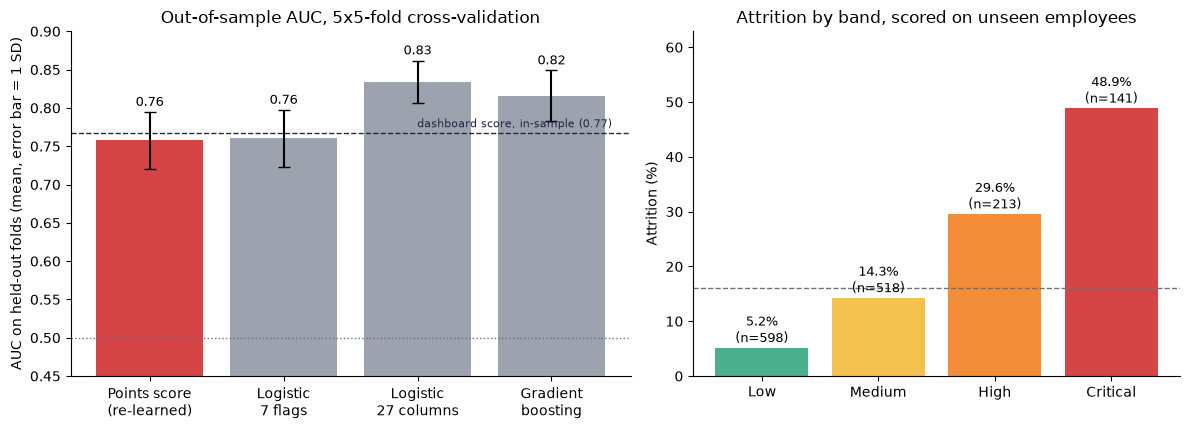

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
short = ["Points score\n(re-learned)", "Logistic\n7 flags", "Logistic\n27 columns", "Gradient\nboosting"]
means = summary["AUC (mean)"].to_numpy()
sds = summary["AUC (std)"].to_numpy()
ax.bar(short, means, yerr=sds, color=["#D64545", "#9CA3AF", "#9CA3AF", "#9CA3AF"], capsize=4)
ax.axhline(0.5, color="#6B7280", linestyle=":", linewidth=1)
ax.axhline(insample["AUC"], color="#1F2A44", linestyle="--", linewidth=1)
ax.text(3.45, insample["AUC"] + 0.008, f"dashboard score, in-sample ({insample['AUC']:.2f})",
        ha="right", fontsize=8, color="#1F2A44")
for i, m in enumerate(means):
    ax.text(i, m + sds[i] + 0.008, f"{m:.2f}", ha="center", fontsize=9)
ax.set_ylim(0.45, 0.9)
ax.set_ylabel("AUC on held-out folds (mean, error bar = 1 SD)")
ax.set_title("Out-of-sample AUC, 5x5-fold cross-validation")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
colours = ["#4CAF8E", "#F2C14E", "#F28C38", "#D64545"]
bars = ax.bar(band_table["oof_band"].astype(str), band_table["attrition_pct"], color=colours)
for bar, pct, n in zip(bars, band_table["attrition_pct"], band_table["headcount"]):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1, f"{pct}%\n(n={n})", ha="center", fontsize=9)
ax.axhline(100 * y.mean(), color="#6B7280", linestyle="--", linewidth=1)
ax.set_ylim(0, max(band_table["attrition_pct"]) + 14)
ax.set_ylabel("Attrition (%)")
ax.set_title("Attrition by band, scored on unseen employees")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig_dir = repo_root() / "reports" / "figures"; fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "03_score_validation.png", dpi=150, bbox_inches="tight")
plt.show()

tables_dir = repo_root() / "reports" / "tables"; tables_dir.mkdir(parents=True, exist_ok=True)
summary.round(4).to_csv(tables_dir / "03_cross_validation_summary.csv")
importance.round(4).to_csv(tables_dir / "03_permutation_importance.csv", index=False)

## 7. Responsible use: does the score flag some groups much more than others?

In [9]:
df["age_band"] = pd.cut(df["age"], [0, 29, 39, 49, 100], labels=["under 30", "30-39", "40-49", "50+"])
df["flagged"] = df["risk_band"].isin(["High", "Critical"]).astype(int)
blocks = []
for col in ["gender", "marital_status", "age_band"]:
    g = (df.groupby(col, observed=True)
           .agg(employees=("flagged", "size"), share_flagged_pct=("flagged", "mean"),
                attrition_pct=("attrition_flag", "mean")).reset_index().rename(columns={col: "group"}))
    g[["share_flagged_pct", "attrition_pct"]] = (100 * g[["share_flagged_pct", "attrition_pct"]]).round(1)
    g.insert(0, "attribute", col)
    blocks.append(g)
pd.concat(blocks, ignore_index=True)

,attribute,group,employees,share_flagged_pct,attrition_pct
0,gender,Female,588,24.8,14.8
1,gender,Male,882,22.9,17.0
2,marital_status,Divorced,327,11.3,10.1
3,marital_status,Married,673,16.2,12.5
4,marital_status,Single,470,43.0,25.5
5,age_band,under 30,326,31.9,27.9
6,age_band,30-39,622,20.1,14.3
7,age_band,40-49,349,23.2,9.7
8,age_band,50+,173,22.0,13.3


## What this shows

1. **The simple score generalises.** On held-out folds its AUC is 0.76 (SD 0.04) against 0.77 in-sample, so the optimism from fitting and testing on the same data is about 0.01. Scored on unseen employees, the bands give 5.2% / 14.3% / 29.6% / 48.9% attrition (Low to Critical), close to the dashboard's in-sample 4.8% / 12.9% / 31.4% / 51.2%.
2. **It is not the strongest predictor, and it does not claim to be.** Logistic regression on all 27 columns reaches AUC 0.83 and finds 67% of leavers in the top 23.7% of staff, against 55% for the points score. Gradient boosting (AUC 0.82) does not beat logistic regression on 1,470 rows. The score trades some accuracy for transparency, and the all-column model uses age, gender and marital status, which should not drive decisions about individuals.
3. **Performance rating stays irrelevant.** Even when a model can see `performance_rating`, it is not among the ten most important columns. `overtime` dominates, followed by `stock_option_level` and `monthly_income`.
4. **Group check.** The score flags 43% of single employees against 11% of divorced and 16% of married ones, and 32% of employees under 30 against 20% to 23% of older groups. Part of that mirrors real attrition gaps (single 25.5%, under 30 27.9%), and the score uses none of these attributes, but they correlate with first-year status and overtime. Use the score in aggregate for workload and onboarding decisions, not to judge individuals.
5. **Limits.** One synthetic dataset; the candidate drivers were chosen while exploring the full data; the fold-to-fold standard deviation (0.04) is larger than the gap between the points score and the 7-flag logistic model (0.758 vs 0.760), so those two are equivalent.